# 07 · Ingenieria de caracteristicas

> **Objetivo:** entender el `ColumnTransformer` que convierte la
> cohorte en matriz lista para scikit-learn, y qué aprende cada
> transformador en el `fit`.

## Que vamos a hacer

1. Revisar los tres bloques del `ColumnTransformer`:
   - `NUM_LOG = ["monetario", "frecuencia", "productos_distintos"]`
     (imputacion por mediana → `log1p` → `StandardScaler`).
   - `NUM_STD = ["recencia", "antiguedad", "tasa_devolucion"]`
     (imputacion por mediana → `StandardScaler`).
   - `CAT = ["pais"]` (`OneHotEncoder(handle_unknown="ignore")`).
2. Inspeccionar los **parametros aprendidos** tras `fit(A)` (medias,
   escalas, categorias).
3. Visualizar como cambia la distribucion antes y despues del `log1p`.

> Para el detalle teorico de cada tecnica, ver
> [`tutorials/07-tecnicas-preprocesamiento.md`](../../../tutorials/07-tecnicas-preprocesamiento.md).
> Aqui aplicamos sobre el caso de recompra.

In [1]:
# Permite importar el paquete segmentacion desde el notebook
import sys
from pathlib import Path

_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

In [2]:
from segmentacion.config import FECHA_CORTE_A, HORIZONTE
from segmentacion.data.cargar import leer_parquet
from segmentacion.data.limpieza import preparar_ventas
from segmentacion.features.cohortes import cohorte
from segmentacion.pipelines.preprocesamiento import CAT, NUM_LOG, NUM_STD, construir_preprocesador

ventas, canc = preparar_ventas(leer_parquet(PROJECT_ROOT / "data" / "raw" / "online_retail_II.parquet"), log=False)
A = cohorte(ventas, canc, FECHA_CORTE_A, horizonte=HORIZONTE)
cols = NUM_LOG + NUM_STD + CAT
XA = A.select(cols).to_pandas()
print(f"columnas de entrada ({len(cols)}): {cols}")
XA.head()

columnas de entrada (7): ['monetario', 'frecuencia', 'productos_distintos', 'recencia', 'antiguedad', 'tasa_devolucion', 'pais']


,monetario,frecuencia,productos_distintos,recencia,antiguedad,tasa_devolucion,pais
0,77556.46,12,27,133,533,0.416667,UK
1,2434.96,4,90,54,212,0.000000,otro
2,1709.40,4,25,56,246,0.000000,otro
3,2671.14,3,90,215,397,0.333333,otro
4,334.40,1,17,118,118,0.000000,otro


## 1. Ajustar el ColumnTransformer con la cohorte A

In [3]:
pre = construir_preprocesador()
XA_prep = pre.fit_transform(XA)
print(f"shape de entrada  : {XA.shape}")
print(f"shape transformada: {XA_prep.shape}  (3 NUM_LOG + 3 NUM_STD + 2 pais_UK/otro = 8)")
nombres = pre.get_feature_names_out()
print(f"columnas de salida: {list(nombres)}")

shape de entrada  : (4933, 7)
shape transformada: (4933, 8)  (3 NUM_LOG + 3 NUM_STD + 2 pais_UK/otro = 8)
columnas de salida: ['log__monetario', 'log__frecuencia', 'log__productos_distintos', 'num__recencia', 'num__antiguedad', 'num__tasa_devolucion', 'cat__pais_UK', 'cat__pais_otro']


## 2. Que aprende el `StandardScaler` del bloque NUM_STD

In [4]:
import pandas as pd

scaler = pre.named_transformers_["num"].named_steps["sc"]
pd.DataFrame({"columna": NUM_STD, "media": scaler.mean_, "desviacion": scaler.scale_})

,columna,media,desviacion
0,recencia,168.707075,141.918162
1,antiguedad,357.187310,154.470623
2,tasa_devolucion,0.207904,0.361766


Estos valores salieron **solo de A**. En `test_sin_fuga.py` se
verifica que coinciden con las medias y desviaciones de A, nunca de
A ∪ B.

## 3. Que aprende el bloque NUM_LOG (imputacion + log1p + scaler)

In [5]:
log_scaler = pre.named_transformers_["log"].named_steps["sc"]
pd.DataFrame({
    "columna": NUM_LOG,
    "media_tras_log1p": log_scaler.mean_,
    "desviacion_tras_log1p": log_scaler.scale_,
})

,columna,media_tras_log1p,desviacion_tras_log1p
0,monetario,6.686602,1.339069
1,frecuencia,1.447153,0.753339
2,productos_distintos,3.641413,1.181894


El `log1p` comprime la cola larga de `monetario`, `frecuencia` y
`productos_distintos`; el `StandardScaler` posterior opera sobre la
distribucion ya comprimida. Esta combinacion es la que la regla 3 de la
Tabla 1 de la spec pide, en respuesta al hallazgo "precio, cantidad y valor
con cola larga" de la U2 (ver `HALLAZGOS.md`).

## 4. Que aprende el OneHotEncoder del bloque CAT

In [6]:
ohe = pre.named_transformers_["cat"]
print(f"categorias aprendidas: {ohe.categories_}")
print(f"handle_unknown: {ohe.handle_unknown}  (si aparece un pais nuevo en inferencia, se ignora)")

categorias aprendidas: [array(['UK', 'otro'], dtype=object)]
handle_unknown: ignore  (si aparece un pais nuevo en inferencia, se ignora)


## 5. Visualizar el efecto del log1p sobre `monetario`

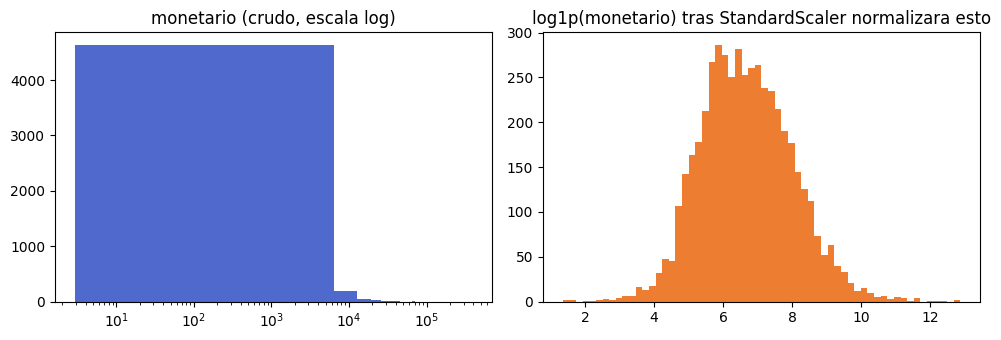

In [7]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(XA["monetario"], bins=60, color="#4F69CC")
axes[0].set_xscale("log")
axes[0].set_title("monetario (crudo, escala log)")
axes[1].hist(np.log1p(XA["monetario"]), bins=60, color="#ED7D31")
axes[1].set_title("log1p(monetario) tras StandardScaler normalizara esto")
plt.tight_layout()
plt.show()

## Preguntas de reflexion

1. ¿Que pasaria si usaramos `MinMaxScaler` en vez de `StandardScaler`?
   ¿Cuando elegirias uno sobre otro?
2. `tasa_devolucion` tiene mediana 0 (la mayoria no devuelve). ¿Por
   que la `SimpleImputer(strategy="median")` no hace daño aqui?
3. Si en U4 llega un cliente de un pais nuevo (p. ej. Nueva Zelanda),
   `handle_unknown="ignore"` lo mapea a vector de ceros. ¿Es un buen
   default? ¿Que alternativa habia?

> **Siguiente paso:** `08_llm_como_transformador.ipynb` (opcional) o
> directamente `09_modelos_y_pipelines.ipynb`.